# Т-Банк: от авиабилета к отелю

**Вопрос:** как часто клиенты бронируют отель после авиабилета и как проверить продуктовую гипотезу о рекомендациях?

Учебная переработка [проекта Kor4yz](https://github.com/Kor4yz/T-bank_analysis_hotels_and_air_travel) на публичной выборке DANO 2024–2025. Коммерческая работа в банке и достигнутый бизнес-эффект не заявляются.

Перед запуском: `python -m pip install -r requirements.txt`, затем `python scripts/download_data.py`.

In [1]:
from pathlib import Path
import os, sys
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
if not (ROOT / "travel").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from travel.data import load_orders
from travel import metrics
from travel.pipeline import run

DATA = Path(os.environ.get("TRAVEL_DATA", str(ROOT / "data/raw/dataset_travel.csv")))
if not DATA.is_file():
    raise FileNotFoundError("Сначала выполните python scripts/download_data.py")
orders, quality = load_orders(DATA)
display(pd.Series(quality, name="value").to_frame())

,value
source_rows,40421
source_clients,30380
non_order_rows,2368
non_order_clients,2368
unknown_type_rows,0
orders,38053
order_clients,28012
missing_status_orders,386
invalid_amount_orders,0
missing_lead_orders,0


## 1. Проверка гранулярности

Не каждая строка CSV — заказ. В метрики входят только AIR/HOT с уникальным `order_rk` и корректной датой создания. Строки без типа заказа учитываются отдельно. Статус SUC означает успех по принятому в исходнике определению; точная история статусов отсутствует.

In [2]:
display(pd.crosstab(orders["order_type_cd"], orders["order_status_cd"].fillna("MISSING")))
assert orders["order_rk"].is_unique
assert quality["source_rows"] == quality["orders"] + quality["non_order_rows"]

order_status_cd,BRN,CNC,ERR,MISSING,NSH,PRC,REJ,SUC
order_type_cd,,,,,,,,
AIR,1,2,35,0,0,877,0,28822
HOT,0,1,0,386,16,0,3,7910


## 2. Стоимость заказов и покрытие статусов

Сумма цен SUC-заказов — номинальная стоимость успешных бронирований. Без комиссии и издержек её нельзя называть выручкой, прибылью или LTV банка. Доли по всем заказам и только известным статусам имеют разные знаменатели.

In [3]:
summary = metrics.summary(orders)
display(summary.round(4))

,product,orders,clients,successful_orders,missing_status,success_share_all,success_share_known,priced_successful_orders,successful_booking_value_rub,mean_successful_booking_rub,median_successful_booking_rub
0,AIR,29737,22268,28822,0,0.9692,0.9692,28822,455573073.0,15806.4351,10252.5
1,HOT,8316,7135,7910,386,0.9512,0.9975,7910,94040451.0,11888.8054,5648.5


## 3. Динамика и глубина бронирования

Последний месяц неполный и выделяется на графике. Один неполный год не устанавливает устойчивую сезонность. Для отелей lead time считается по календарным датам. Медианные цены по группам — описательная связь; она может объясняться составом поездок и длительностью проживания.

In [4]:
display(metrics.monthly(orders))
display(metrics.hotel_lead(orders).round(4))

,month,product,orders,successful_orders,successful_booking_value_rub,exclude_from_full_month_comparison
0,2024-01,AIR,2691,2602,38244120.0,False
1,2024-01,HOT,590,560,8304838.0,False
2,2024-02,AIR,2579,2497,39984790.0,False
3,2024-02,HOT,630,593,8170401.0,False
4,2024-03,AIR,2688,2585,42061854.0,False
5,2024-03,HOT,803,777,9412930.0,False
6,2024-04,AIR,2817,2718,41192342.0,False
7,2024-04,HOT,877,845,9835200.0,False
8,2024-05,AIR,2855,2764,40401236.0,False
9,2024-05,HOT,819,781,9639199.0,False


,lead_days,orders,successful_orders,success_share_all,missing_status,median_successful_booking_rub,mean_successful_booking_rub
0,0,1818,1723,0.9477,87,3665.0,6475.5711
1,1–3,2130,2032,0.9540,92,5113.0,9512.4744
2,4–7,1072,1028,0.9590,42,6234.0,12034.8249
3,8–14,958,908,0.9478,49,7685.0,13864.9934
4,15–30,1060,1016,0.9585,42,7738.5,16130.4094
5,31+,1278,1203,0.9413,74,9007.0,18457.1771


## 4. Повторные покупки

Когорта — месяц первой наблюдаемой успешной покупки. Это не обязательно месяц первого привлечения клиента. M1 показывает покупку в следующем календарном месяце. M0 по определению равен 100%; ещё не наблюдавшиеся месяцы — NaN, не ноль.

In [5]:
retention, sizes = metrics.cohort_retention(orders)
display(sizes.to_frame())
display((retention * 100).round(2))

,clients
cohort,
2024-01,2962
2024-02,2679
2024-03,2783
2024-04,2795
2024-05,2693
2024-06,2871
2024-07,2855
2024-08,2678
2024-09,2435


age_month,0,1,2,3,4,5,6,7,8,9
cohort,,,,,,,,,,
2024-01,100.0,7.22,6.72,7.02,6.48,5.81,5.84,5.37,4.79,5.37
2024-02,100.0,6.27,6.16,5.71,6.05,5.49,5.49,4.70,5.04,NaN
2024-03,100.0,6.47,5.28,5.10,5.50,5.10,4.89,5.17,NaN,NaN
2024-04,100.0,5.26,5.22,4.40,4.90,4.36,4.65,NaN,NaN,NaN
2024-05,100.0,6.50,5.31,5.53,4.57,5.09,NaN,NaN,NaN,NaN
2024-06,100.0,5.75,5.82,4.28,4.63,NaN,NaN,NaN,NaN,NaN
2024-07,100.0,5.81,4.83,4.94,NaN,NaN,NaN,NaN,NaN,NaN
2024-08,100.0,5.27,5.97,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-09,100.0,5.54,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 5. AIR → HOT с полным окном наблюдения

Один якорь на клиента: первый наблюдаемый AIR с SUC. Исключаются клиенты с HOT до или одновременно с якорем. HOT должен быть строго позже и в пределах окна. В знаменатель входят только клиенты, которым до конца наблюдения доступны все 7/30/60 дней, независимо от наличия события. Для каждого окна знаменатель свой.

Связь с одной поездкой не доказана. Временная история за пределами CSV неизвестна. Интервал Wilson оценивает неопределённость доли, а не репрезентативность выборки.

In [6]:
cross_sell = metrics.cross_sell(orders)
display(cross_sell.round(6))

,window_days,air_clients,excluded_prior_or_same_time_hot,eligible_clients,excluded_short_followup,hotel_clients,cross_sell_share,wilson_lower,wilson_upper
0,7,21778,599,20836,343,93,0.004463,0.003645,0.005464
1,30,21778,599,19563,1616,200,0.010223,0.008907,0.011732
2,60,21778,599,17800,3379,308,0.017303,0.015489,0.019326


## 6. Почему эффект промокодов здесь не оценивается

Пропуск скидки не равен нулевой скидке. Проверяем покрытие по продуктам, прежде чем сравнивать группы. Даже при полном покрытии назначение промокодов могло быть неслучайным.

In [7]:
display(metrics.promo_coverage(orders))
display(metrics.destinations(orders))

,product,orders,missing_discount,zero_discount,positive_discount,negative_discount
0,AIR,29737,0,29397,340,0
1,HOT,8316,8287,0,29,0


,destination,successful_orders,product
0,Москва,1108,HOT
1,Санкт-Петербург,653,HOT
2,Сочи,266,HOT
3,Казань,177,HOT
4,Стамбул,164,HOT
5,Дубай,163,HOT
6,Екатеринбург,143,HOT
7,Эсто-Садок,127,HOT
8,Нижний Новгород,112,HOT
9,Краснодар,108,HOT


## 7. Полный воспроизводимый отчёт

Пайплайн сохраняет агрегированные CSV, графики и HTML. SQL-запросы выполняются в SQLite и автоматически сверяются с pandas. Индивидуальные клиентские данные в отчёт не экспортируются.

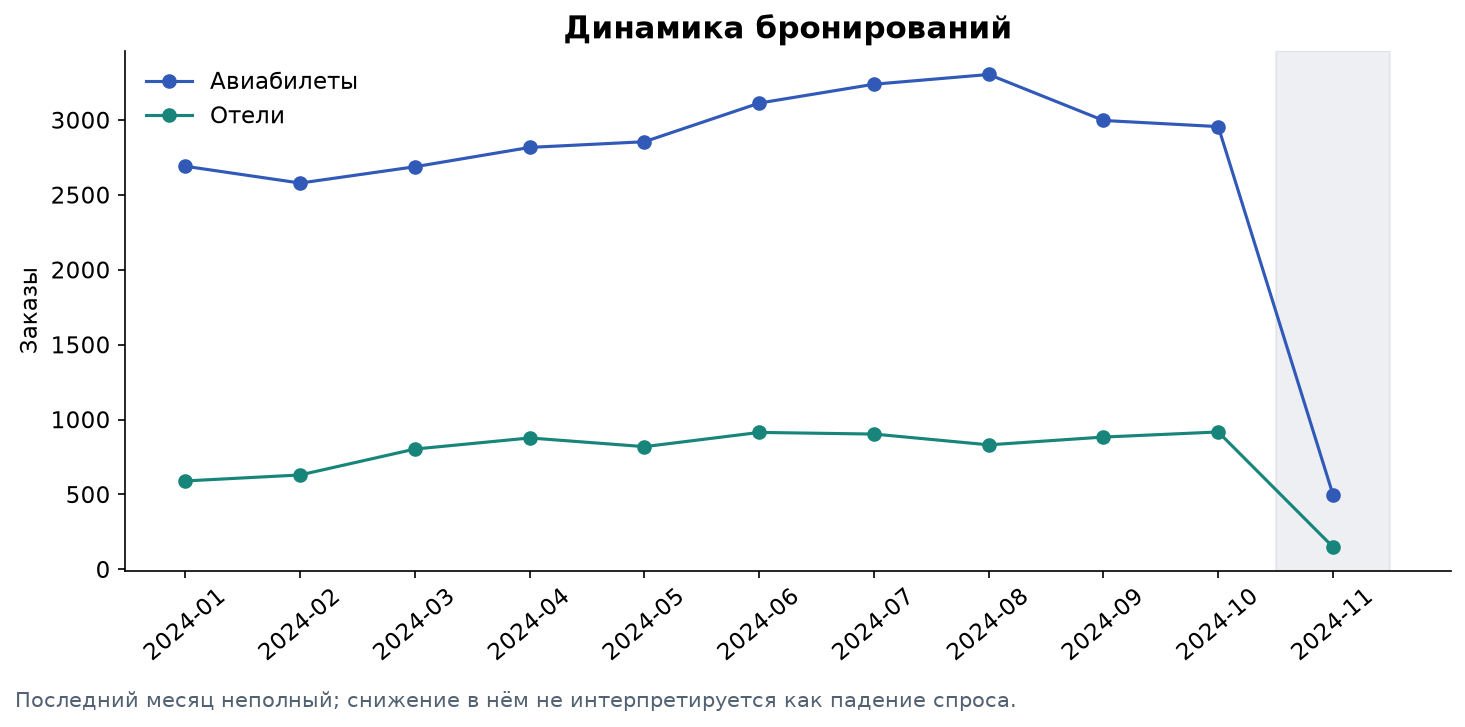

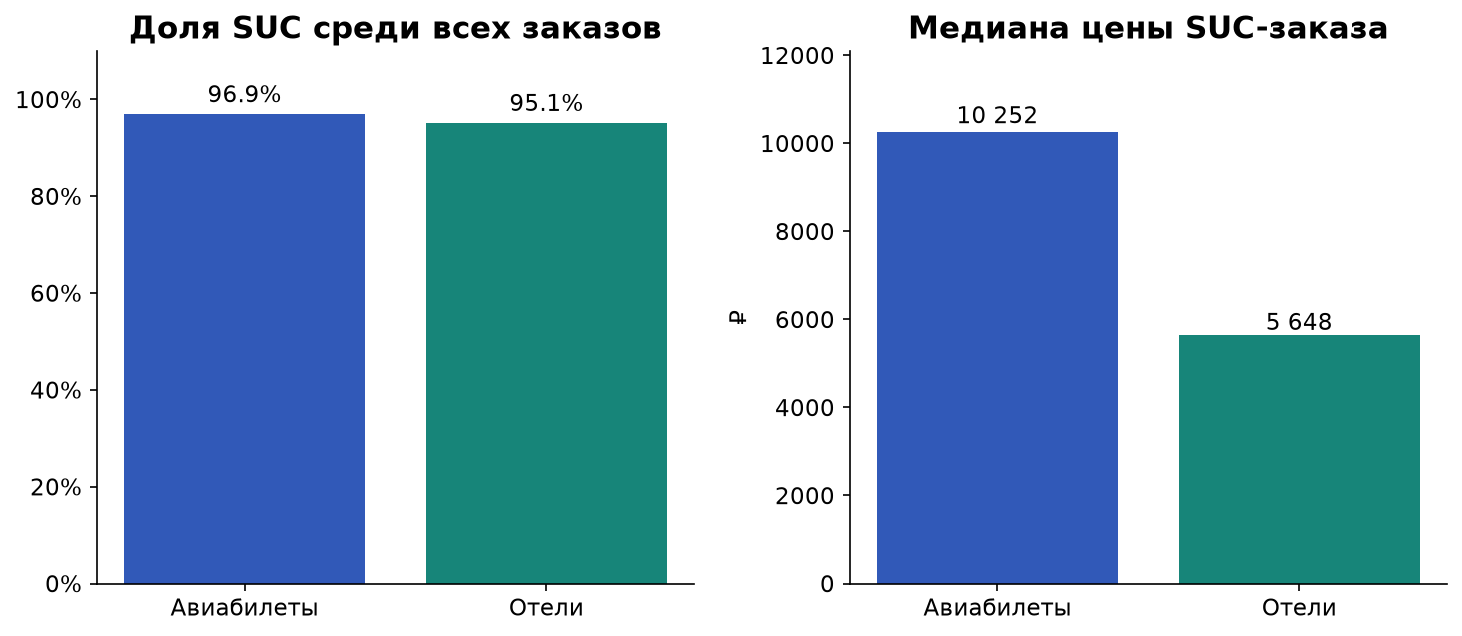

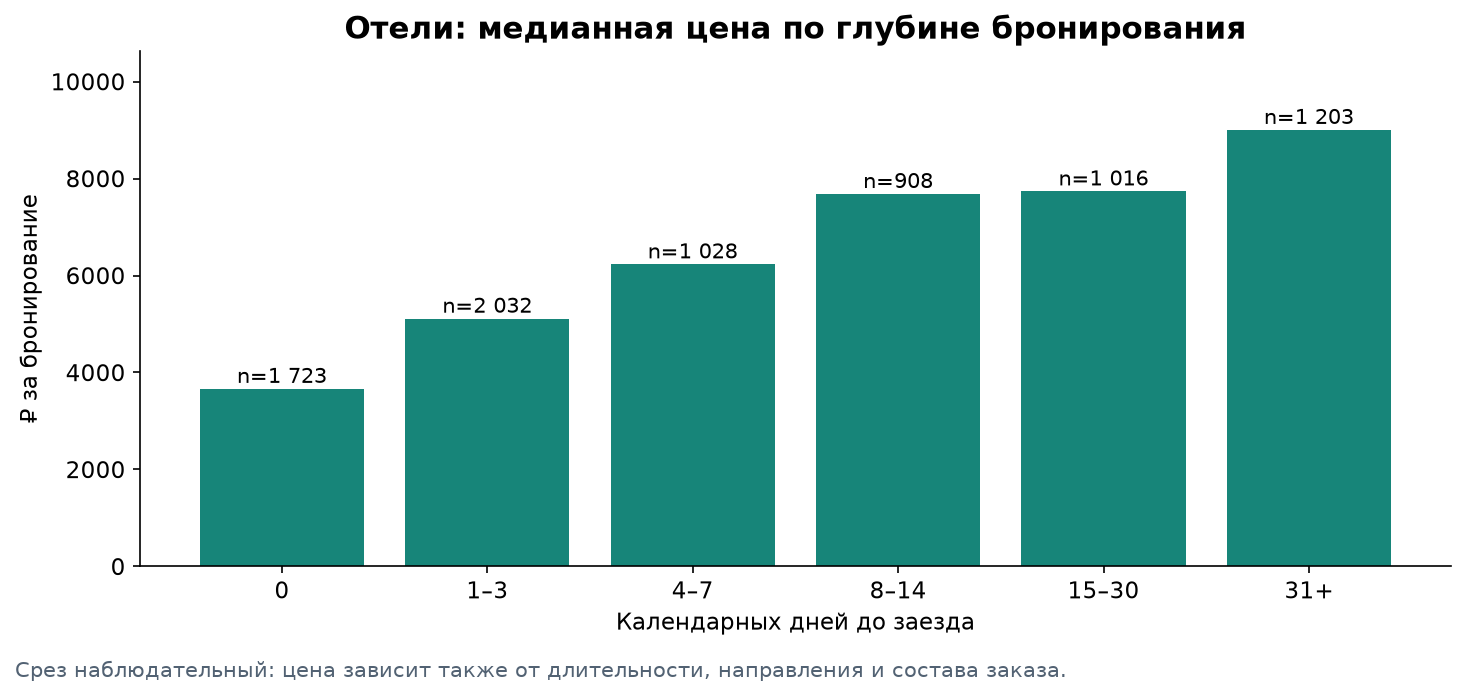

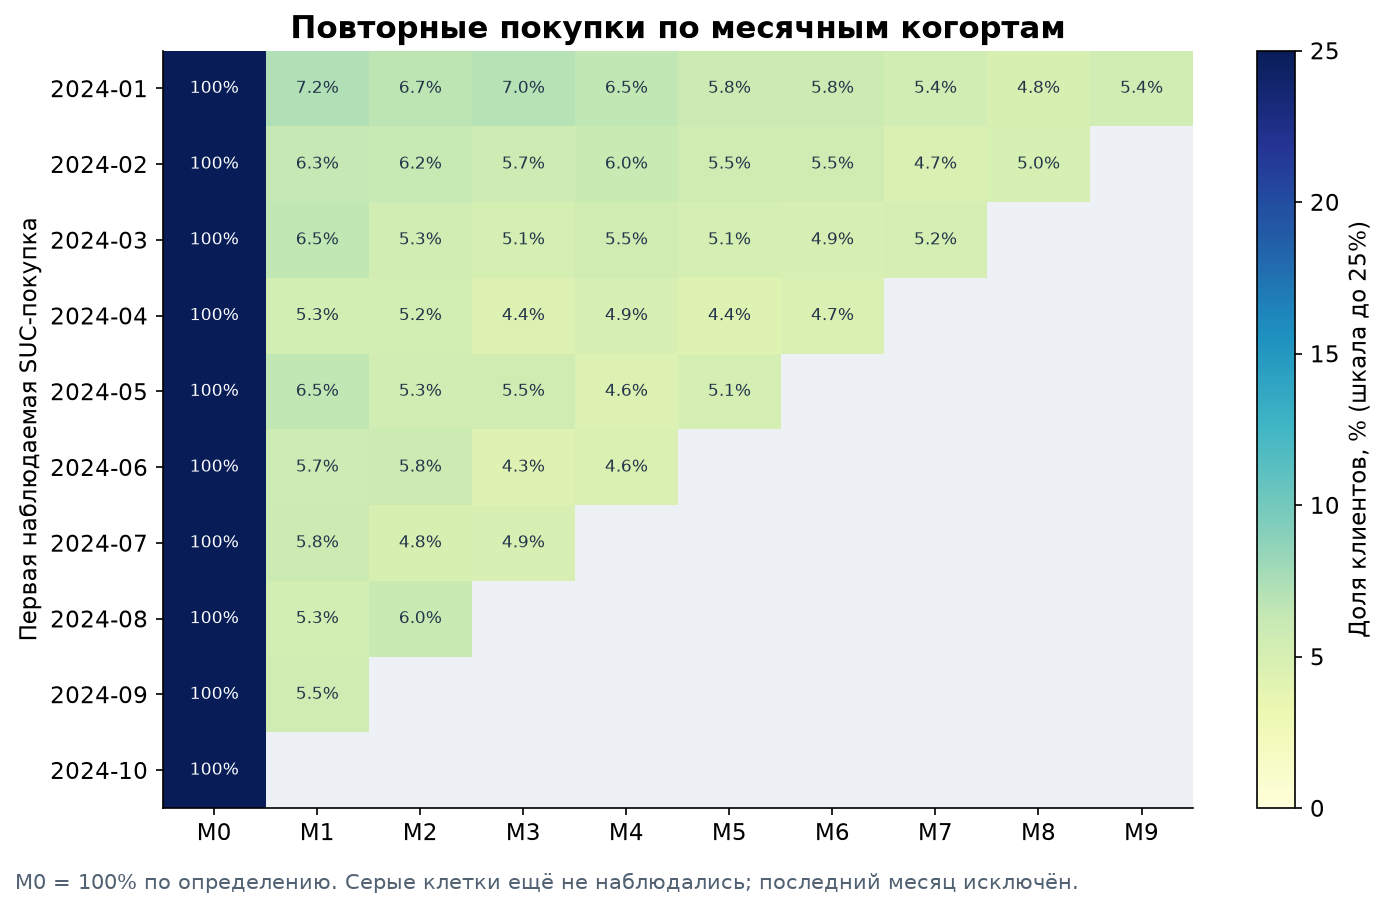

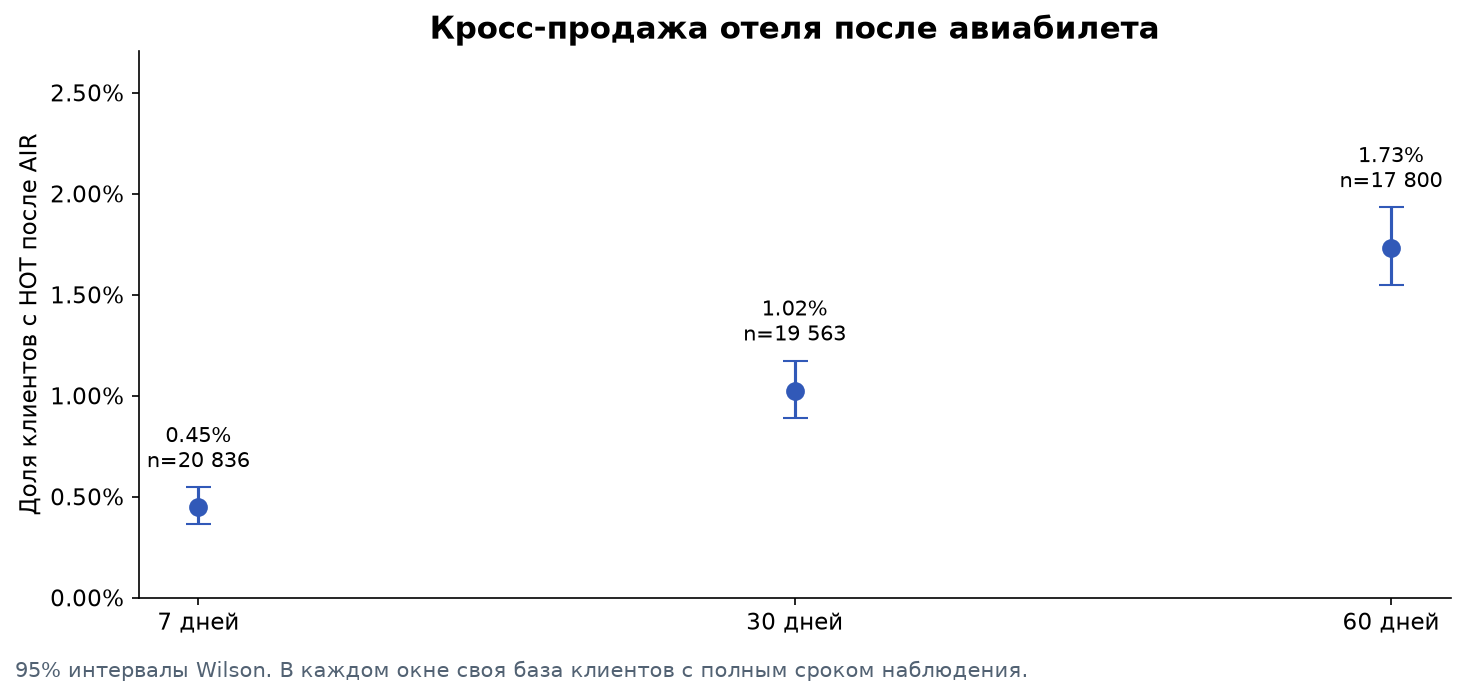

In [8]:
tables, quality = run(DATA, ROOT / "reports")
for path in sorted((ROOT / "reports/figures").glob("*.png")):
    display(Image(filename=str(path)))

## 8. План A/B-теста

Предложение: рекомендации отелей после AIR-покупки. Рандомизация по клиентам 50/50. Primary: доля клиентов с HOT за полные 30 дней, ITT. α=0,05, мощность 80%, основной MDE +20% относительно baseline. Контролировать отмены, обращения, задержку интерфейса и маржу. Ниже — приближённый расчёт числа клиентов; подходящий трафик и длительность набора неизвестны. Тест не проводился.

In [9]:
display(tables["experiment_plan"])
display(Markdown((ROOT / "reports/analysis.md").read_text(encoding="utf-8")))

,relative_mde,baseline,target,clients_per_group,total_clients
0,0.1,0.010223,0.011246,159494,318988
1,0.2,0.010223,0.012268,41750,83500
2,0.3,0.010223,0.013290,19389,38778


# Т-Банк: возможности кросс-продаж в путешествиях

Учебный проект по публичной выборке. Переработка исходного анализа, без заявлений о работе в Т-Банке.

## Что показали данные

- В выборке 40 421 строк и 38 053 заказов за 2024-01-01 — 2024-11-06. 2 368 строк без типа заказа учитываются отдельно.
- У 200 из 19 563 подходящих клиентов есть успешный заказ отеля в течение 30 дней после первой наблюдаемой успешной покупки авиабилета: 1.02%. 95% интервал Wilson: 0.89%–1.17%.
- Для 30-дневного окна исключены 1 616 клиентов с недостаточным сроком наблюдения и 599 клиентов с отелем до или одновременно с авиабилетом.
- Доля SUC среди всех заказов: авиабилеты 96.92%, отели 95.12%. У 386 гостиничных заказов статус отсутствует. Среди известных статусов HOT доля SUC равна 99.75%; это другой знаменатель, а не улучшение конверсии.
- Медианная цена успешного заказа: авиабилеты 10 252 ₽, отели 5 648 ₽. Точные значения без округления сохранены в CSV.
- Максимум заказов среди полных наблюдаемых месяцев — 2024-07: 4 142. Ноябрь неполный, декабрь отсутствует. Одного неполного года недостаточно для вывода об устойчивой сезонности.
- У 8 287 из 8 316 гостиничных заказов (99.65%) не заполнена скидка. Пропуск не означает отсутствие промокода; эффект скидок по этому срезу не оценивается.

## Определения и ограничения

- Единица анализа — уникальный order_rk для строк AIR/HOT. Клиентские строки без типа заказа исключены из метрик бронирований. Повторяющиеся ID или некорректная дата создания останавливают расчёт.
- SUC используется как операционное определение успешного заказа, унаследованное из исходного проекта. Статусы отражают состояние в выгрузке; даты перехода в SUC отсутствуют. Полный справочник статусов не опубликован в проверенном описании.
- Сумма nominal_price_rub_amt для SUC — номинальная стоимость успешных бронирований. Это не комиссионная выручка, прибыль, ARPU или LTV банка. Финансовые возвраты и комиссия неизвестны.
- Для кросс-продажи выбран один якорь на клиента: дата первого наблюдаемого AIR со статусом SUC. HOT должен быть строго позже и не позднее конца окна. Ранее наблюдаемые HOT исключаются. Для каждого окна отдельно исключается неполное наблюдение; окна нельзя трактовать как одну кумулятивную кривую одной когорты.
- Конец наблюдения принят равным максимальной дате создания заказа в CSV. Это техническая граница выгрузки, не подтверждённая дата окончания сбора всех событий. Связь заказов с одной поездкой не установлена; история до января и покупки вне сервиса не наблюдаются.
- Когорты строятся по первой наблюдаемой SUC-покупке, а не по привлечению нового клиента. Retention M1 — доля клиентов когорты с SUC в следующем календарном месяце. M0 всегда 100%. Последний месяц исключён, будущие клетки остаются пустыми.
- Глубина бронирования отелей — разность календарных дат заезда и создания заказа. Время суток обнуляется, чтобы покупка в день заезда не становилась отрицательным lead time. Единого подтверждённого часового пояса нет; близкие к полуночи случаи требуют проверки источника.
- Для медианы и среднего используются только SUC с известной неотрицательной суммой. Выбросы не обрезаются. Интервалы Wilson относятся к клиентской доле кросс-продаж и не учитывают смещение отбора выборки.

## Следующий шаг: дизайн A/B-теста

- Гипотеза: релевантный блок отелей после успешной покупки авиабилета увеличит долю клиентов, бронирующих отель в течение 30 дней.
- Единица рандомизации — клиент, распределение 50/50 с постоянным закреплением варианта. Включать один раз после первого подходящего AIR. Исключать уже бронировавших HOT по полной доступной истории; это более точное условие, чем доступное в учебной выборке.
- Контроль — текущий интерфейс, тест — блок отелей по месту назначения и датам, если они достоверно известны. Основная метрика: доля рандомизированных клиентов с успешной HOT-покупкой за 30 дней, анализ по назначенной группе (ITT).
- Порог решения фиксируется заранее: двусторонний α=0.05, мощность 80%, относительный MDE 20%. Окно наблюдения каждой группы — полные 30 дней. Не завершать тест досрочно по случайному достижению значимости.
- Защитные метрики: отмены и возвраты, обращения в поддержку, задержка страницы, отписки. Для бизнес-решения дополнительно нужны комиссия, маржа и стоимость стимула. Проверить SRM и корректность событий до оценки эффекта.
- Плановый размер выборки рассчитан приближением для двух независимых долей, без поправки на потери и последовательный просмотр. Исторический baseline служит ориентиром: период, eligibility и аудиторию будущего теста нужно сверить. Длительность набора зависит от реального подходящего трафика и здесь не заявляется.
- Это план эксперимента. A/B-тест на этих данных не проводился, рост конверсии и финансовый эффект не доказаны.

## Что переработано

- Длинный Colab-скрипт заменён модулями загрузки, метрик, графиков и отчёта; запуск через CLI без ручного редактирования путей.
- Разделены строки клиентов и заказы; добавлены проверки ключей, дат, денежных значений и покрытия статусов.
- Уточнены финансовые определения; убраны выводы о выручке банка, LTV и декабрьском пике.
- Кросс-продажи пересчитаны с одним якорем на клиента, исключением ранних HOT и контролем полного окна.
- В когортной таблице различаются ноль повторных покупок и ещё не наблюдавшийся период.
- Добавлены SQL-запросы с автоматической сверкой против pandas, тесты граничных случаев, проверка SHA-256 и выполненный ноутбук.

## Источники

- [Официальное описание набора DANO 2024–2025](https://dano.hse.ru/data2024)
- [Словарь полей Т-Банка](https://dano.hse.ru/mirror/pubs/share/987926897.pdf)
- [Исходный проект Дениса Морозова (Kor4yz)](https://github.com/Kor4yz/T-bank_analysis_hotels_and_air_travel)

Версия исходных данных: `a8739c64927a7fc4a0398adac55ba8c033ffe7cd67ff42cbf7533bdf8a50c211`.
Расчёты и таблицы: `tables/`. Графики: `figures/`.
